# 02 · Diagnóstico do score atual (baseline)

Antes de construir um modelo novo, precisamos entender **o que estamos tentando superar**: quão bem
o score em produção ordena o risco, se ele é estável no tempo e **onde ele falha**. Os pontos fracos
do modelo atual indicam onde o novo modelo pode gerar valor.

> Como o score já vem de um modelo treinado fora deste projeto, podemos avaliá-lo na base inteira sem
> risco de vazamento. Ainda assim, separamos os números por partição para comparar com o novo modelo
> no mesmo período de teste (notebook 07).

In [1]:
# Configuração comum a todos os notebooks do projeto
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import matplotlib.pyplot as plt

from fraude import config as cfg, dados, metricas, graficos as gr

gr.aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)

In [2]:
df = dados.carregar_base()
y, s = df["fraude"], df["score"]
df.shape

(150000, 21)

## 1. Por que essas métricas?

| Métrica | O que mede | Por que usar aqui |
|---|---|---|
| **ROC AUC** | probabilidade de uma fraude receber score maior que uma legítima | padrão de mercado, independe do corte |
| **PR AUC (AP)** | precisão média ao longo do recall | **foca na classe rara**; o ROC AUC pode parecer bom mesmo com muitos falsos positivos |
| **KS** | separação máxima entre as distribuições | métrica tradicional em risco |
| **Recall @ FPR x%** | % das fraudes capturadas bloqueando x% dos bons | traduz o trade-off para a linguagem do negócio |
| **Lucro (R$)** | resultado financeiro de uma política de corte | métrica de **decisão** (notebook 08) |

Uma referência útil: um score **aleatório** tem ROC AUC = 0,5 e PR AUC = taxa de fraude (≈ 0,05).

In [3]:
tabela = pd.concat(
    [metricas.resumo(y, s, df["monto"], nome="Base completa")] +
    [metricas.resumo(g["fraude"], g["score"], g["monto"], nome=p.capitalize())
     for p, g in df.groupby("particao", sort=False)], axis=1)
tabela

,Base completa,Treino,Validacao,Teste
ROC AUC,0.7263,0.7246,0.7295,0.7264
PR AUC (AP),0.1765,0.1519,0.2549,0.2269
KS,0.4315,0.4124,0.4491,0.4535
Recall @ FPR 1%,0.0854,0.0650,0.1341,0.1579
Recall @ FPR 5%,0.3026,0.2472,0.4012,0.4180
Recall @ FPR 10%,0.4759,0.4166,0.5248,0.5274
Recall R$ @ FPR 5%,0.2985,0.2406,0.4025,0.4410


O score atual tem **poder discriminante moderado**: ROC AUC ≈ 0,73 e PR AUC ≈ 0,18 (3,5x o aleatório).
Bloqueando 5% dos clientes bons, ele captura só ~30% das fraudes. Há espaço relevante para melhorar.

## 2. Como o score se distribui

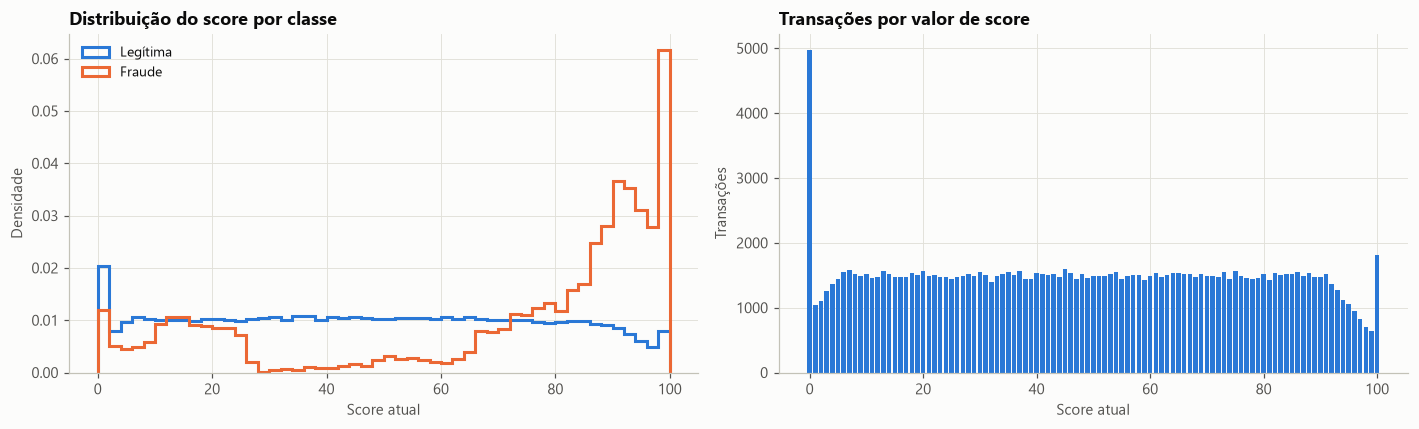

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.arange(0, 102, 2)
for alvo in [0, 1]:
    axes[0].hist(s[y == alvo], bins=bins, density=True, histtype="step", lw=2,
                 color=gr.COR_ALVO[alvo], label=gr.ROTULO_ALVO[alvo])
axes[0].set(title="Distribuição do score por classe", xlabel="Score atual", ylabel="Densidade")
axes[0].legend()

contagem = s.value_counts().sort_index()
axes[1].bar(contagem.index, contagem.values, color=gr.AZUL, width=0.8)
axes[1].set(title="Transações por valor de score", xlabel="Score atual", ylabel="Transações")
plt.tight_layout()

- Fora os extremos (0 e 100), **cada valor de score concentra ≈ 1% da base**. O score é, na prática,
  um **percentil** de risco, e não uma probabilidade. Consequência: ele não pode ser usado diretamente em
  regras de custo esperado (`p × custo`) sem calibração.
- A distribuição das fraudes é **bimodal**. Há o pico esperado em scores altos, mas também uma
  **massa relevante de fraudes em scores baixos** (0–25). Vamos olhar isso de perto.

## 3. A "zona cega" do score atual

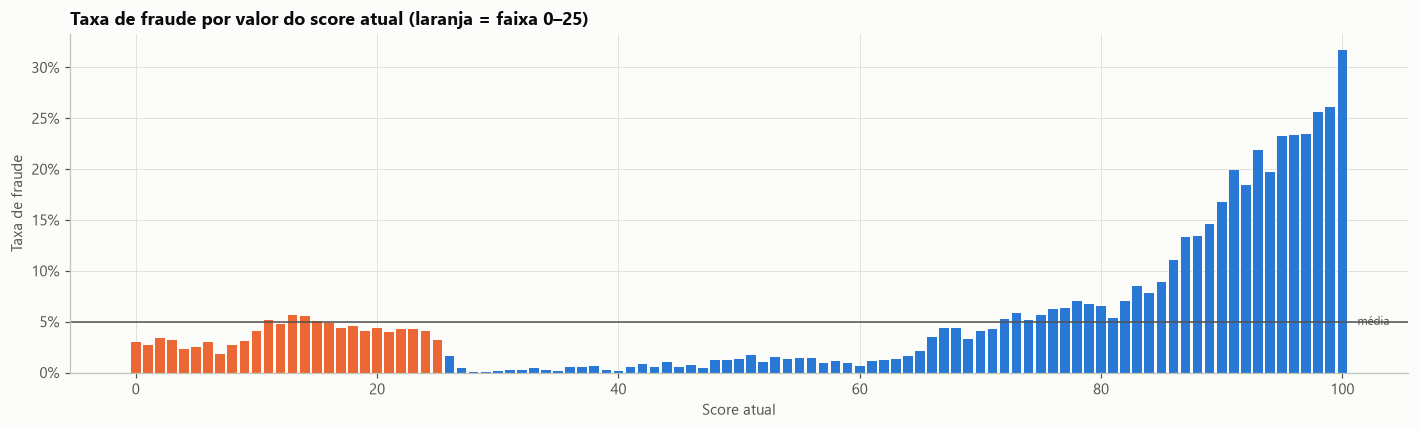

In [5]:
taxa_por_score = df.groupby("score")["fraude"].mean()

fig, ax = plt.subplots(figsize=(13, 4))
cores = np.where(taxa_por_score.index <= 25, gr.LARANJA, gr.AZUL)
ax.bar(taxa_por_score.index, taxa_por_score.values, color=cores, width=0.8)
ax.axhline(y.mean(), color=gr.TINTA_2, lw=1)
ax.text(101, y.mean(), " média", va="center", fontsize=8, color=gr.TINTA_2)
ax.set(title="Taxa de fraude por valor do score atual (laranja = faixa 0–25)",
       xlabel="Score atual", ylabel="Taxa de fraude")
gr.formatar_pct(ax)
plt.tight_layout()

In [6]:
faixa = pd.cut(s, [-1, 25, 29, 60, 80, 100], labels=["0–25", "26–29", "30–60", "61–80", "81–100"])
zona = df.groupby(faixa, observed=True).agg(transacoes=("fraude", "size"), fraudes=("fraude", "sum"),
                                            taxa_fraude=("fraude", "mean"))
zona["%_transacoes"] = zona["transacoes"] / len(df)
zona["%_das_fraudes"] = zona["fraudes"] / y.sum()
# ROC AUC *dentro* de cada faixa: o score ainda ordena o risco ali dentro?
zona["auc_dentro_da_faixa"] = df.groupby(faixa, observed=True).apply(
    lambda g: roc_auc_score(g["fraude"], g["score"]) if g["fraude"].nunique() > 1 else np.nan)
zona

,transacoes,fraudes,taxa_fraude,%_transacoes,%_das_fraudes,auc_dentro_da_faixa
score,,,,,,
0–25,41268,1572,0.0381,0.2751,0.2096,0.5445
26–29,5971,33,0.0055,0.0398,0.0044,0.2128
30–60,46460,363,0.0078,0.3097,0.0484,0.6292
61–80,29987,1287,0.0429,0.1999,0.1716,0.6295
81–100,26314,4245,0.1613,0.1754,0.5660,0.6538


**Esse é o principal achado sobre o modelo atual:**

- Na faixa **0–25**, que reúne ~28% das transações, a taxa de fraude é ~3,8%, **próxima da média da
  base**. Dentro dela o score **praticamente não ordena o risco** (AUC ≈ 0,54, perto do aleatório). O modelo atribui "risco baixo"
  sem conseguir distinguir fraude de legítima.
- Essa faixa concentra **~21% de todas as fraudes**. Como qualquer política de corte aprova os scores
  baixos, **essas fraudes passam sempre**, independentemente do ponto de corte escolhido.
- Logo acima (26–29) a taxa despenca para ~0,5%, e a partir daí o score volta a ser crescente
  (quanto maior o score, maior o risco).

Esse comportamento é típico de um **segmento que o modelo não cobre**, como uma população sem
histórico, uma regra de *fallback* ou uma falha de integração que gera score baixo por padrão. Num
projeto real, levaríamos o achado ao time dono do modelo. Para nós, é uma **oportunidade clara**: se o
novo modelo identificar essas fraudes, o ganho é direto.

Será que dá para ver o risco nessa faixa com as variáveis disponíveis? Um teste rápido com a variável `o`:

In [7]:
tab = (df.assign(faixa_score=np.where(s <= 25, "score 0–25", "score > 25"), o=df["o"].fillna("nulo"))
         .pivot_table(index="o", columns="faixa_score", values="fraude", aggfunc="mean"))
tab.style.format("{:.1%}")

faixa_score,score 0–25,score > 25
o,,
N,11.7%,24.3%
Y,9.0%,5.2%
nulo,1.6%,2.2%


Mesmo dentro da zona cega, transações com `o = N` têm **~12% de fraude** e `o = nulo` só ~1,6%.
Há sinal nos dados que o score atual não aproveita nessa população.

## 4. Estabilidade no tempo

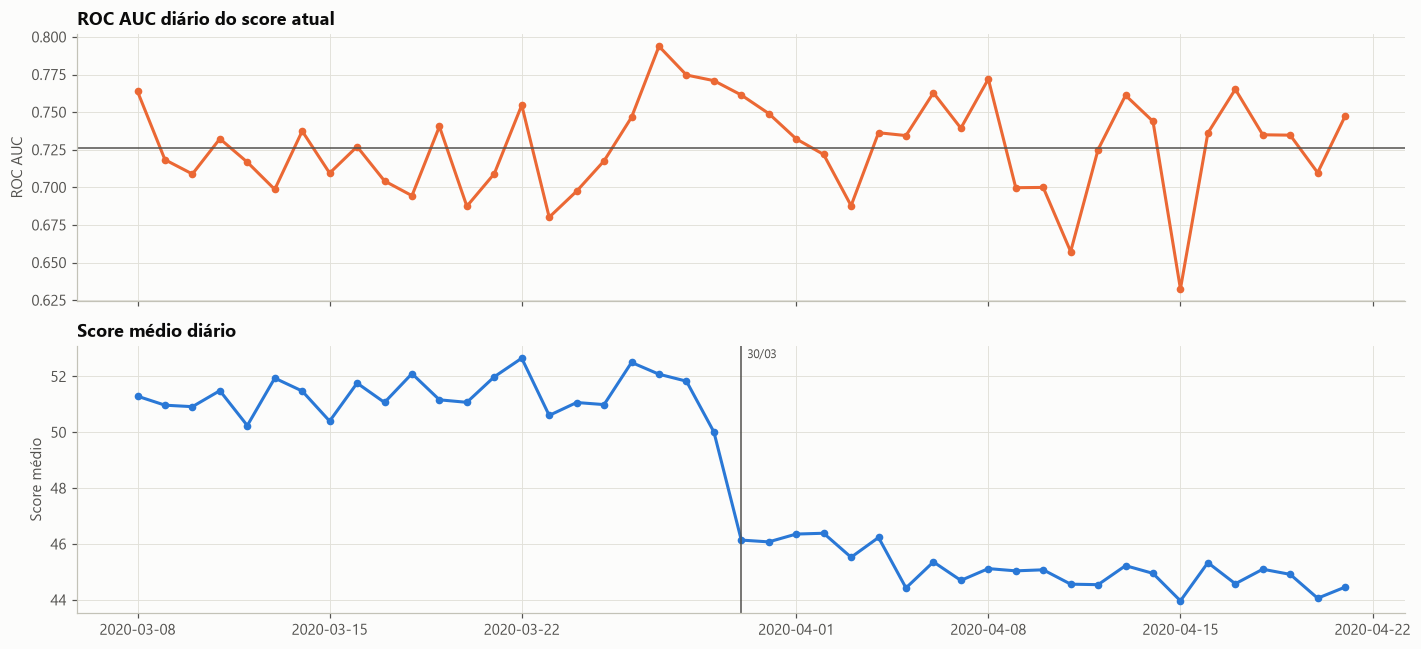

In [8]:
dia = df["fecha"].dt.normalize()
estab = df.groupby(dia).apply(lambda g: pd.Series({
    "roc_auc": roc_auc_score(g["fraude"], g["score"]),
    "score_medio": g["score"].mean(),
}))

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
axes[0].plot(estab.index, estab["roc_auc"], color=gr.LARANJA, marker="o", ms=4)
axes[0].axhline(roc_auc_score(y, s), color=gr.TINTA_2, lw=1)
axes[0].set(title="ROC AUC diário do score atual", ylabel="ROC AUC")
axes[1].plot(estab.index, estab["score_medio"], color=gr.AZUL, marker="o", ms=4)
axes[1].axvline(pd.Timestamp("2020-03-30"), color=gr.TINTA_2, lw=1)
axes[1].text(pd.Timestamp("2020-03-30"), estab["score_medio"].max(), "  30/03", fontsize=8, color=gr.TINTA_2)
axes[1].set(title="Score médio diário", ylabel="Score médio")
plt.tight_layout()

In [9]:
# PSI semanal do score contra a primeira semana (referência)
semana = df["fecha"].dt.to_period("W-SAT")
ref = df.loc[semana == semana.min(), "score"]
psi_semanal = pd.Series({str(w.start_time.date()): metricas.psi(ref, g["score"])
                         for w, g in df.groupby(semana)}, name="PSI vs 1ª semana")
psi_semanal.to_frame().T

,2020-03-08,2020-03-15,2020-03-22,2020-03-29,2020-04-05,2020-04-12,2020-04-19
PSI vs 1ª semana,0.0000,0.0007,0.0013,0.0474,0.0746,0.0854,0.0850


- O **ROC AUC diário oscila entre ~0,63 e ~0,79**. A pior leitura é 15/04, o dia atípico identificado
  no notebook 01.
- O **score médio cai de ~51 para ~45 a partir de 30/03** e se mantém nesse novo patamar. Esse degrau
  sugere uma **mudança no modelo ou na população** (retreino, nova versão, mudança de mix). O PSI fica
  baixo (< 0,1, considerado estável), então a mudança é sutil na distribuição. Mas é exatamente o tipo
  de evento que um monitoramento produtivo deve sinalizar.

## 5. Baseline a ser batido (período de teste)

In [10]:
teste = df[df["particao"] == "teste"]
baseline = metricas.resumo(teste["fraude"], teste["score"], teste["monto"], nome="Score atual — teste OOT")
baseline.to_frame()

,Score atual — teste OOT
ROC AUC,0.7264
PR AUC (AP),0.2269
KS,0.4535
Recall @ FPR 1%,0.1579
Recall @ FPR 5%,0.4180
Recall @ FPR 10%,0.5274
Recall R$ @ FPR 5%,0.4410


## 6. Conclusões

1. **Desempenho moderado:** ROC AUC ≈ 0,73, PR AUC ≈ 0,18 e KS ≈ 0,43 na base completa. No teste
   (11/04–21/04), ROC AUC ≈ 0,73 e PR AUC ≈ 0,23.
2. **O score é um percentil, não uma probabilidade.** Para decisões por custo esperado será preciso
   escolher o corte empiricamente (notebook 08).
3. **Zona cega em 0–25:** ~21% das fraudes recebem score baixo e passam por qualquer política de
   corte. Dentro dessa faixa o score é equivalente a um sorteio, mas há sinal nos dados (ex.: `o`).
4. **Instabilidade:** AUC diário variando bastante e um degrau no score médio em 30/03, o que mostra
   que o modelo em produção precisa de monitoramento.

➡️ **Próximo passo (03):** explorar as variáveis para encontrar os sinais que o score atual não usa.